# IMDb Movie Analysis Project

**Objective:** Analyze movies by genre, gross revenue, ratings, and regional categories (Bollywood vs. Tollywood).


In [1]:
import re
import time
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Website Request

Check whether IMDb's website is accessible. A status code of 200 means the request succeeded.


In [2]:

url = "https://www.imdb.com/"
headers = {
    "User-Agent": "Mozilla/5.0"
}
response = requests.get(url, headers=headers, timeout=30)
print("Status Code:", response.status_code)

Status Code: 202


## 3. Inspect Website Response

Check the response status, page title, and a short preview of the returned HTML.


In [3]:

print("Status Code:", response.status_code)
print("Final URL:", response.url)
print("Content Type:", response.headers.get("Content-Type"))
print("Response Preview:")
print(response.text[:500])

Status Code: 202
Final URL: https://www.imdb.com/
Content Type: text/html; charset=UTF-8
Response Preview:



## 4. Check the Response Content

In [4]:

print("Status:", response.status_code)
print("Content length:", len(response.text))
print("Response encoding:", response.encoding)
print("Response headers:")

for key, value in response.headers.items():
    print(key, ":", value)

Status: 202
Content length: 0
Response encoding: UTF-8
Response headers:
Content-Type : text/html; charset=UTF-8
Content-Length : 0
Connection : keep-alive
Server : Server
Date : Fri, 09 Oct 2026 15:48:51 GMT
Vary : User-Agent,Accept-Encoding
x-amzn-waf-action : challenge
Cache-Control : no-store, max-age=0
Access-Control-Allow-Origin : *
Access-Control-Max-Age : 86400
Access-Control-Allow-Methods : OPTIONS,GET,POST
Access-Control-Expose-Headers : x-amzn-waf-action
x-amz-rid : HG1AJ97QNT4Y27W70DA9
Strict-Transport-Security : max-age=47474747; includeSubDomains; preload
Edge-Cache-Control : no-store,no-cache,stale-if-error=0,stale-while-revalidate=0
X-Cache : Miss from cloudfront
Via : 1.1 43f8989e9a738af1408c91cdf67ba906.cloudfront.net (CloudFront)
X-Amz-Cf-Pop : HYD57-P6
Alt-Svc : h3=":443"; ma=86400
X-Amz-Cf-Id : P3X-yzBTGX84PyC36EEgZxBVDEGAk53Tilli7tB-jtKFkuxO_2lsGQ==


## 5. IMDb Data Collection

IMDb provides official downloadable datasets for movie titles, genres, release years, ratings, and vote counts. We will use these datasets if your trainer approves this alternative to direct website scraping.


## 6. Collect IMDb Movie Data

Load movie information from IMDb's official downloadable datasets into Pandas DataFrames. These datasets provide movie titles, release years, genres, ratings, and vote counts.


In [5]:
import pandas as pd

basics_url = "https://datasets.imdbws.com/title.basics.tsv.gz"

basics = pd.read_csv(
    basics_url,
    sep="\t",
    na_values="\\N",
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", basics.shape)
print("Column names:")
print(basics.columns.tolist())

display(basics.head())

Dataset loaded successfully!
Dataset shape: (12849219, 9)
Column names:
['tconst', 'titleType', 'primaryTitle', 'originalTitle', 'isAdult', 'startYear', 'endYear', 'runtimeMinutes', 'genres']


,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0000001,short,Carmencita,Carmencita,0,1894.0,NaN,1,"Documentary,Short"
1,tt0000002,short,Le clown et ses chiens,Le clown et ses chiens,0,1892.0,NaN,5,"Animation,Short"
2,tt0000003,short,Poor Pierrot,Pauvre Pierrot,0,1892.0,NaN,5,"Animation,Comedy,Romance"
3,tt0000004,short,Un bon bock,Un bon bock,0,1892.0,NaN,12,"Animation,Short"
4,tt0000005,short,Blacksmith Scene,Blacksmith Scene,0,1893.0,NaN,1,Short


### 6.2 Verify the movie filter

Filter the IMDb dataset to include feature films and television movies for analysis.


In [6]:


print("All IMDb records:", len(basics))

print("\nTitle types:")
print(basics["titleType"].value_counts().head(15))

print("\nMovie counts:")
print(basics["titleType"].isin(["movie", "tvMovie"]).sum())


All IMDb records: 12849219

Title types:
titleType
tvEpisode       9936757
short           1162287
movie            758982
video            332070
tvSeries         306566
tvMovie          156510
tvMiniSeries      73476
tvSpecial         60948
videoGame         50546
tvShort           11076
tvPilot               1
Name: count, dtype: int64

Movie counts:
915492


### 6.3 Load Movie Ratings

Load IMDb's ratings dataset, which contains average ratings and the number of votes for each title.


In [7]:

ratings_url = "https://datasets.imdbws.com/title.ratings.tsv.gz"

ratings = pd.read_csv(
    ratings_url,
    sep="\t",
    na_values="\\N"
)

print("Ratings dataset shape:", ratings.shape)
display(ratings.head())

Ratings dataset shape: (1718579, 3)


,tconst,averageRating,numVotes
0,tt0000001,5.7,2231
1,tt0000002,5.4,326
2,tt0000003,6.4,2391
3,tt0000004,5.0,202
4,tt0000005,6.2,3097


## 6.4 — Check movie counts

In [8]:

print("Total rows in basics:", len(basics))

print("\nTitle types:")
print(basics["titleType"].value_counts().head(15))

print("\nFeature movies:")
print((basics["titleType"] == "movie").sum())

print("\nTV movies:")
print((basics["titleType"] == "tvMovie").sum())

Total rows in basics: 12849219

Title types:
titleType
tvEpisode       9936757
short           1162287
movie            758982
video            332070
tvSeries         306566
tvMovie          156510
tvMiniSeries      73476
tvSpecial         60948
videoGame         50546
tvShort           11076
tvPilot               1
Name: count, dtype: int64

Feature movies:
758982

TV movies:
156510


## 6.5 — Load a larger movie sample

In [9]:

import pandas as pd

basics_url = "https://datasets.imdbws.com/title.basics.tsv.gz"

movie_chunks = []

for chunk in pd.read_csv(
    basics_url,
    sep="\t",
    na_values="\\N",
    chunksize=200_000,
    low_memory=False
):
    movie_chunk = chunk[chunk["titleType"] == "movie"]
    movie_chunks.append(movie_chunk)

movies = pd.concat(movie_chunks, ignore_index=True)

print("Total feature movies:", len(movies))
display(movies.head())

Total feature movies: 758982


,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres
0,tt0000009,movie,Miss Jerry,Miss Jerry,0,1894.0,NaN,45.0,Romance
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,0,1897.0,NaN,100.0,"Documentary,News,Sport"
2,tt0000502,movie,Bohemios,Bohemios,0,1905.0,NaN,100.0,NaN
3,tt0000574,movie,The Story of the Kelly Gang,The Story of the Kelly Gang,0,1906.0,NaN,70.0,"Action,Adventure,Biography"
4,tt0000591,movie,The Prodigal Son,L'enfant prodigue,0,1907.0,NaN,90.0,Drama


### 6.6 Merge Movie Details and Ratings

Merge the movie details and IMDb ratings datasets using `tconst`, the unique IMDb title identifier.


In [10]:

movies = movies.merge(
    ratings,
    on="tconst",
    how="left"
)

print("Merged dataset shape:", movies.shape)
print("Columns:", movies.columns.tolist())

display(movies.head())

Merged dataset shape: (758982, 11)
Columns: ['tconst', 'titleType', 'primaryTitle', 'originalTitle', 'isAdult', 'startYear', 'endYear', 'runtimeMinutes', 'genres', 'averageRating', 'numVotes']


,tconst,titleType,primaryTitle,originalTitle,isAdult,startYear,endYear,runtimeMinutes,genres,averageRating,numVotes
0,tt0000009,movie,Miss Jerry,Miss Jerry,0,1894.0,NaN,45.0,Romance,5.3,239.0
1,tt0000147,movie,The Corbett-Fitzsimmons Fight,The Corbett-Fitzsimmons Fight,0,1897.0,NaN,100.0,"Documentary,News,Sport",5.3,614.0
2,tt0000502,movie,Bohemios,Bohemios,0,1905.0,NaN,100.0,NaN,3.9,28.0
3,tt0000574,movie,The Story of the Kelly Gang,The Story of the Kelly Gang,0,1906.0,NaN,70.0,"Action,Adventure,Biography",6.0,1097.0
4,tt0000591,movie,The Prodigal Son,L'enfant prodigue,0,1907.0,NaN,90.0,Drama,5.0,42.0


### 6.7 Check Missing Values

Identify missing values in the merged dataset before cleaning the data.


In [11]:

print("Missing values in each column:")
print(movies.isnull().sum())

print("\nExact duplicate rows:", movies.duplicated().sum())

Missing values in each column:
tconst                 0
titleType              0
primaryTitle           3
originalTitle          3
isAdult                0
startYear         113674
endYear           758982
runtimeMinutes    271513
genres             77921
averageRating     409166
numVotes          409166
dtype: int64

Exact duplicate rows: 0


## 7. Data Cleaning

### 7.1 Handle Missing Values

Remove records without a movie title, release year, or genre. Keep unrated movies in the original dataset, but use rated movies for rating analysis.


In [12]:

# Create a copy for cleaning
movies_clean = movies.copy()

# Remove rows without essential information
movies_clean = movies_clean.dropna(
    subset=["primaryTitle", "startYear", "genres"]
)

# Convert release year to integer
movies_clean["startYear"] = movies_clean["startYear"].astype(int)

# Remove the irrelevant endYear column for feature movies
movies_clean = movies_clean.drop(columns=["endYear"])

print("Original dataset shape:", movies.shape)
print("Cleaned dataset shape:", movies_clean.shape)
print("\nMissing values after cleaning:")
print(movies_clean.isnull().sum())

Original dataset shape: (758982, 11)
Cleaned dataset shape: (574380, 10)

Missing values after cleaning:
tconst                 0
titleType              0
primaryTitle           0
originalTitle          0
isAdult                0
startYear              0
runtimeMinutes    122226
genres                 0
averageRating     236075
numVotes          236075
dtype: int64


## 7.2 Create a dataset for rating analysis

In [13]:

rated_movies = movies_clean.dropna(
    subset=["averageRating", "numVotes"]
).copy()

print("Movies available for rating analysis:", len(rated_movies))
display(rated_movies[
    ["primaryTitle", "startYear", "genres", "averageRating", "numVotes"]
].head())

Movies available for rating analysis: 338305


,primaryTitle,startYear,genres,averageRating,numVotes
0,Miss Jerry,1894,Romance,5.3,239.0
1,The Corbett-Fitzsimmons Fight,1897,"Documentary,News,Sport",5.3,614.0
3,The Story of the Kelly Gang,1906,"Action,Adventure,Biography",6.0,1097.0
4,The Prodigal Son,1907,Drama,5.0,42.0
5,Robbery Under Arms,1907,Drama,3.7,38.0


## 8. Save Cleaned Data

Export the cleaned movie dataset and the rated movie dataset to CSV files for further analysis and project submission.


In [14]:

movies_clean.to_csv("imdb_movies_cleaned.csv", index=False)

rated_movies.to_csv("imdb_rated_movies.csv", index=False)

print("Cleaned movie dataset saved successfully!")
print("Rated movie dataset saved successfully!")

Cleaned movie dataset saved successfully!
Rated movie dataset saved successfully!


## 9. Exploratory Data Analysis (EDA)

### 9.1 Summary Statistics

Examine the distribution of movie release years, runtimes, ratings, and vote counts.


In [15]:

print("Movie dataset information:")
movies_clean.info()

print("\nNumerical summary:")
display(
    rated_movies[
        ["startYear", "runtimeMinutes", "averageRating", "numVotes"]
    ].describe()
)

Movie dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 574380 entries, 0 to 758981
Data columns (total 10 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   tconst          574380 non-null  object 
 1   titleType       574380 non-null  object 
 2   primaryTitle    574380 non-null  object 
 3   originalTitle   574380 non-null  object 
 4   isAdult         574380 non-null  int64  
 5   startYear       574380 non-null  int64  
 6   runtimeMinutes  452154 non-null  object 
 7   genres          574380 non-null  object 
 8   averageRating   338305 non-null  float64
 9   numVotes        338305 non-null  float64
dtypes: float64(2), int64(2), object(6)
memory usage: 48.2+ MB

Numerical summary:


,startYear,averageRating,numVotes
count,338305.000000,338305.000000,3.383050e+05
mean,1998.265367,6.153275,3.844485e+03
std,26.095829,1.376361,3.885298e+04
min,1894.000000,1.000000,5.000000e+00
25%,1983.000000,5.300000,2.200000e+01
50%,2009.000000,6.300000,6.900000e+01
75%,2018.000000,7.100000,3.480000e+02
max,2026.000000,10.000000,3.249383e+06


## 9.2 Top 10 highest-rated movies

In [16]:

top_rated = (
    rated_movies[rated_movies["numVotes"] >= 1000]
    .sort_values("averageRating", ascending=False)
    [["primaryTitle", "startYear", "genres", "averageRating", "numVotes"]]
    .head(10)
)

display(top_rated)

,primaryTitle,startYear,genres,averageRating,numVotes
624702,Maa Ramudu Andarivadu,2026,"Action,Family,Romance",9.9,1015.0
562694,Om Ka Hari,2026,"Comedy,Drama",9.9,5019.0
385731,In Medias Res,2011,Thriller,9.9,1179.0
549688,Anbil Avan,2026,"Action,Drama,Romance",9.8,2079.0
559750,Anireekshitha Atithigalu,2026,"Drama,Thriller",9.8,1646.0
633062,Oye Chill Maar,2026,"Comedy,Drama",9.7,2087.0
617741,The Red Bag,2026,"Action,Drama,Mystery",9.7,1041.0
616797,Happy Journey,2026,"Comedy,Drama",9.7,1383.0
633771,Tutt Paini English Ne,2026,Comedy,9.7,1030.0
616436,Rudrabhishekam,2026,Drama,9.6,1013.0


## 10. Genre-wise Movie Analysis

### 10.1 Number of Movies by Genre

Count the number of movies belonging to each genre to identify the most common genres in the dataset. Movies with multiple genres will be counted in each applicable genre.


In [17]:

genre_counts = (
    movies_clean.assign(
        genres=movies_clean["genres"].str.split(",")
    )
    .explode("genres")
    .groupby("genres")
    .size()
    .sort_values(ascending=False)
)

print("Top 10 genres by movie count:")
display(genre_counts.head(10))

Top 10 genres by movie count:


genres
Drama          241764
Documentary    141220
Comedy         110155
Action          50129
Romance         49640
Thriller        38479
Crime           38414
Horror          34552
Adventure       26992
Family          18072
dtype: int64

## 10.2 Visualize the top 10 genres

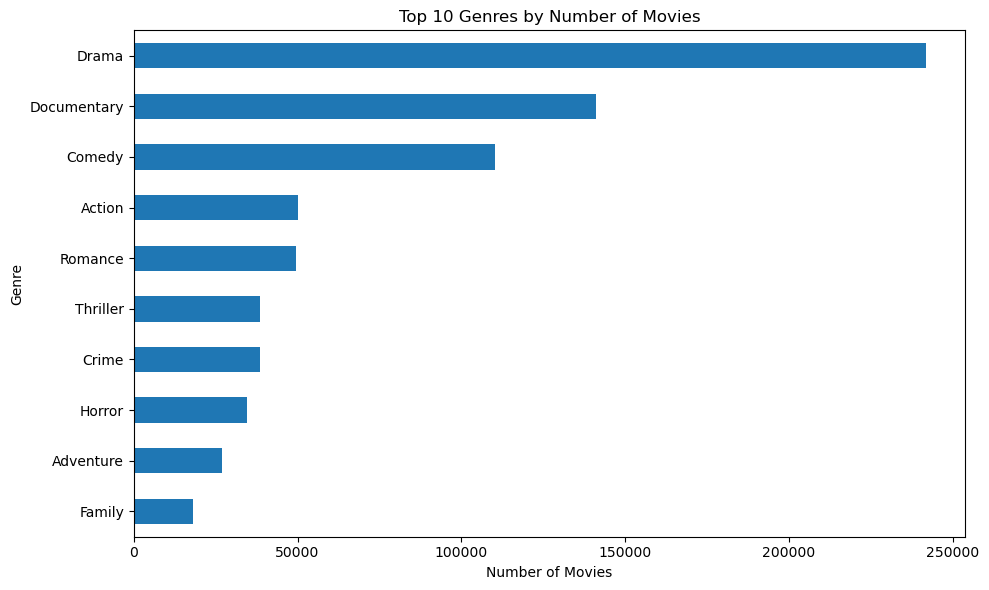

In [18]:

plt.figure(figsize=(10, 6))

genre_counts.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Genres by Number of Movies")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

## 10.3 Average rating by genre

In [19]:

rated_genres = rated_movies.assign(
    genres=rated_movies["genres"].str.split(",")
).explode("genres")

genre_ratings = (
    rated_genres.groupby("genres")
    .agg(
        movie_count=("averageRating", "count"),
        average_rating=("averageRating", "mean")
    )
    .query("movie_count >= 100")
    .sort_values("average_rating", ascending=False)
)

print("Top 10 genres by average rating (at least 100 rated movies):")
display(genre_ratings.head(10))

Top 10 genres by average rating (at least 100 rated movies):


,movie_count,average_rating
genres,,
News,687,7.180932
Documentary,57645,7.172280
Biography,11192,6.922293
Music,9535,6.808138
History,9889,6.764021
Sport,4541,6.639947
Film-Noir,876,6.463470
Reality-TV,102,6.460784
War,6833,6.364569


## step: 11. Ratings Analysis

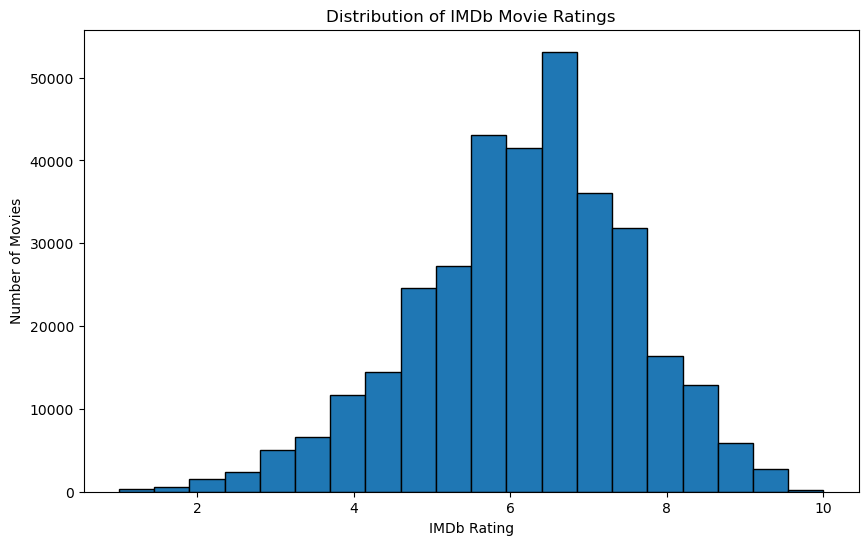

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

rated_movies["averageRating"].plot(
    kind="hist",
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of IMDb Movie Ratings")
plt.xlabel("IMDb Rating")
plt.ylabel("Number of Movies")

plt.show()

In [24]:

import pandas as pd

data_url = "https://raw.githubusercontent.com/ThomasFurtado/Movies-Dataset-IMDb/main/movies.csv"

gross_data = pd.read_csv(data_url)

# Save the downloaded data as a CSV in your current folder
gross_data.to_csv("movie_gross.csv", index=False)

print("Movie dataset downloaded and saved successfully!")
print("Dataset shape:", gross_data.shape)
print("Columns:", gross_data.columns.tolist())

display(gross_data.head())

Movie dataset downloaded and saved successfully!
Dataset shape: (7668, 15)
Columns: ['name', 'rating', 'genre', 'year', 'released', 'score', 'votes', 'director', 'writer', 'star', 'country', 'budget', 'gross', 'company', 'runtime']


,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


## 12. Gross Revenue Analysis

**Objective:** To analyze movie gross revenue and identify the highest-grossing movies.


**Note:** Gross revenue data is not available in the IMDb title basics and ratings datasets used in this project. An additional authorized dataset containing movie titles and gross revenue is required for this analysis.


In [25]:

# Step 12: Gross Revenue Analysis

# Remove movies without gross revenue
gross_clean = gross_data.dropna(subset=["gross"]).copy()

# Find the 10 highest-grossing movies
top_grossing = gross_clean.sort_values(
    by="gross", ascending=False
).head(10)

# Display movie names and gross revenue
display(top_grossing[["name", "year", "genre", "gross"]])

,name,year,genre,gross
5445,Avatar,2009,Action,2.847246e+09
7445,Avengers: Endgame,2019,Action,2.797501e+09
3045,Titanic,1997,Drama,2.201647e+09
6663,Star Wars: Episode VII - The Force Awakens,2015,Action,2.069522e+09
7244,Avengers: Infinity War,2018,Action,2.048360e+09
7480,The Lion King,2019,Animation,1.670728e+09
6653,Jurassic World,2015,Action,1.670516e+09
6043,The Avengers,2012,Action,1.518816e+09
6646,Furious 7,2015,Action,1.515341e+09
7494,Frozen II,2019,Animation,1.450027e+09


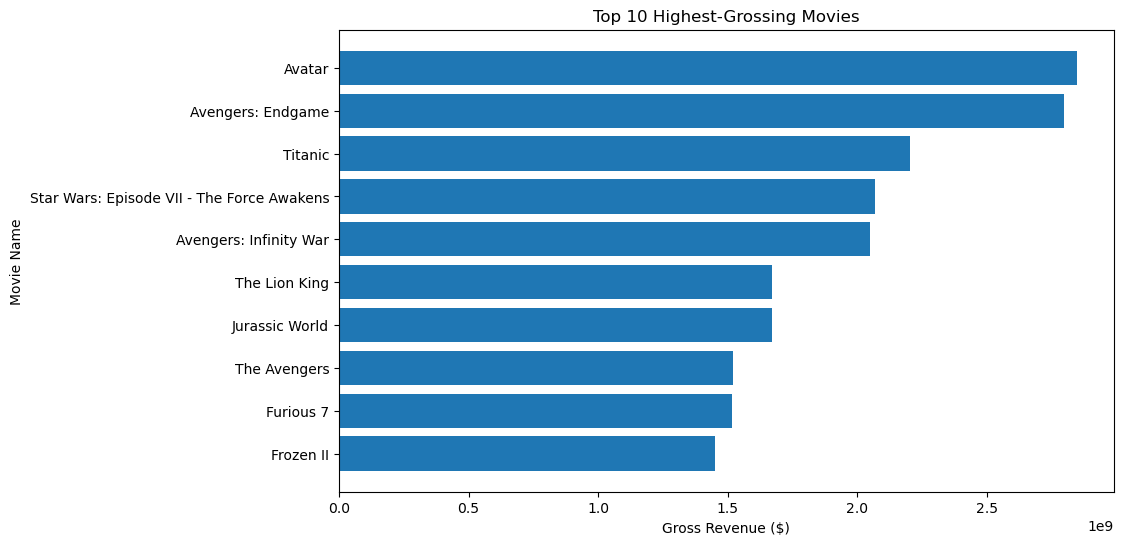

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(top_grossing["name"], top_grossing["gross"])

plt.title("Top 10 Highest-Grossing Movies")
plt.xlabel("Gross Revenue ($)")
plt.ylabel("Movie Name")

plt.gca().invert_yaxis()
plt.show()

## 13: Bollywood vs Tollywood Analysis

In [27]:

# Step 13: Regional Movie Analysis

print("Available columns:")
print(gross_data.columns.tolist())

print("\nMovies by country:")
display(gross_data["country"].value_counts().head(10))

Available columns:
['name', 'rating', 'genre', 'year', 'released', 'score', 'votes', 'director', 'writer', 'star', 'country', 'budget', 'gross', 'company', 'runtime']

Movies by country:


country
United States     5475
United Kingdom     816
France             279
Canada             190
Germany            117
Australia           92
Japan               81
India               62
Italy               61
Spain               47
Name: count, dtype: int64

In [28]:

# Select movies produced in India
indian_movies = gross_data[
    gross_data["country"].str.contains("India", case=False, na=False)
].copy()

print("Total Indian movies:", len(indian_movies))

display(
    indian_movies[
        ["name", "year", "genre", "score", "gross"]
    ].sort_values("year")
)

Total Indian movies: 62


,name,year,genre,score,gross
3325,Kuch Kuch Hota Hai,1998,Comedy,7.6,NaN
3800,Hey Ram,2000,Crime,7.9,274675.0
3835,Kaho Naa... Pyaar Hai,2000,Action,6.9,NaN
3962,Lagaan: Once Upon a Time in India,2001,Drama,8.1,1724806.0
3975,Dil Chahta Hai,2001,Comedy,8.1,316221.0
...,...,...,...,...,...
7585,Kalank,2019,Drama,3.6,17987034.0
7575,Gully Boy,2019,Drama,8.0,28141995.0
7555,Chhichhore,2019,Comedy,8.3,3311391.0
7590,Saaho,2019,Action,5.2,5708522.0


In [29]:

# Remove Indian movies without an IMDb score
indian_rated = indian_movies.dropna(subset=["score"]).copy()

# Find the top 10 movies by IMDb score
top_indian_movies = indian_rated.sort_values(
    by="score", ascending=False
).head(10)

display(top_indian_movies[["name", "year", "genre", "score"]])

,name,year,genre,score
4596,Black Friday,2004,Action,8.5
6917,Dangal,2016,Action,8.4
5466,3 Idiots,2009,Comedy,8.4
5134,Like Stars on Earth,2007,Drama,8.4
7555,Chhichhore,2019,Comedy,8.3
7191,Baahubali 2: The Conclusion,2017,Action,8.2
5926,Zindagi Na Milegi Dobara,2011,Comedy,8.2
5814,Udaan,2010,Drama,8.2
4835,Black,2005,Drama,8.2
6384,Bhaag Milkha Bhaag,2013,Biography,8.2


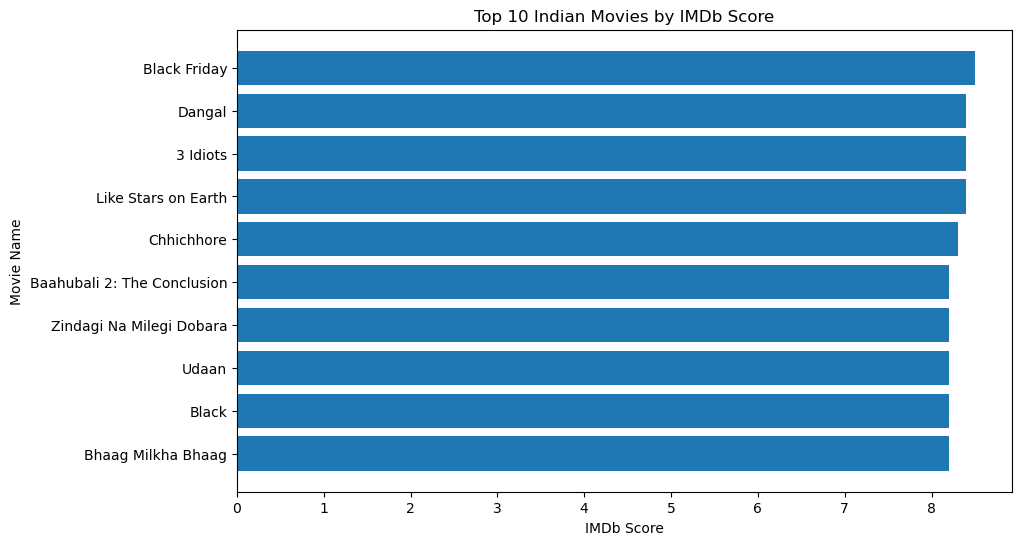

In [30]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(top_indian_movies["name"], top_indian_movies["score"])

plt.title("Top 10 Indian Movies by IMDb Score")
plt.xlabel("IMDb Score")
plt.ylabel("Movie Name")

plt.gca().invert_yaxis()
plt.show()

In [31]:
print("Indian movie columns:")
print(indian_movies.columns.tolist())

print("\nTotal Indian movies:", len(indian_movies))

display(indian_movies[["name", "year", "country", "genre", "score"]].head(10))

Indian movie columns:
['name', 'rating', 'genre', 'year', 'released', 'score', 'votes', 'director', 'writer', 'star', 'country', 'budget', 'gross', 'company', 'runtime']

Total Indian movies: 62


,name,year,country,genre,score
3325,Kuch Kuch Hota Hai,1998,India,Comedy,7.6
3800,Hey Ram,2000,India,Crime,7.9
3835,Kaho Naa... Pyaar Hai,2000,India,Action,6.9
3962,Lagaan: Once Upon a Time in India,2001,India,Drama,8.1
3975,Dil Chahta Hai,2001,India,Comedy,8.1
3989,Kabhi Khushi Kabhie Gham...,2001,India,Drama,7.4
4013,Monsoon Wedding,2001,India,Comedy,7.4
4115,Devdas,2002,India,Drama,7.6
4363,Kal Ho Naa Ho,2003,India,Comedy,7.9
4587,Swades,2004,India,Drama,8.2


## 14.2 — Check the Indian movies available

In [32]:
print("Indian movies by year:")
display(
    indian_movies[["name", "year", "score", "gross"]]
    .sort_values("year")
)

Indian movies by year:


,name,year,score,gross
3325,Kuch Kuch Hota Hai,1998,7.6,NaN
3800,Hey Ram,2000,7.9,274675.0
3835,Kaho Naa... Pyaar Hai,2000,6.9,NaN
3962,Lagaan: Once Upon a Time in India,2001,8.1,1724806.0
3975,Dil Chahta Hai,2001,8.1,316221.0
...,...,...,...,...
7585,Kalank,2019,3.6,17987034.0
7575,Gully Boy,2019,8.0,28141995.0
7555,Chhichhore,2019,8.3,3311391.0
7590,Saaho,2019,5.2,5708522.0


## 14.3 — Prepare the Bollywood vs Tollywood comparison

In [33]:
print("Movies with IMDb scores:", indian_movies["score"].notna().sum())
print("Movies with gross revenue:", indian_movies["gross"].notna().sum())
print("Movies with missing gross revenue:", indian_movies["gross"].isna().sum())

Movies with IMDb scores: 62
Movies with gross revenue: 59
Movies with missing gross revenue: 3


## 14.4 — Check whether your data has language information

In [34]:
print(indian_movies.columns.tolist())

['name', 'rating', 'genre', 'year', 'released', 'score', 'votes', 'director', 'writer', 'star', 'country', 'budget', 'gross', 'company', 'runtime']


## 14.5 — Let's check your existing dataset first

In [35]:
print(indian_movies["country"].value_counts())
print("\nAvailable genres:")
print(indian_movies["genre"].unique())

country
India    62
Name: count, dtype: int64

Available genres:
['Comedy' 'Crime' 'Action' 'Drama' 'Mystery' 'Biography']


In [36]:
import pandas as pd

indian_data = pd.read_csv("indianmovies.csv")

print("Shape:", indian_data.shape)
print("Columns:", indian_data.columns.tolist())

display(indian_data.head())

Shape: (250, 9)
Columns: ['Unnamed: 0', 'Rank', 'Movie Names', 'Links', 'Rating', 'Year', 'Duration_of_movie', 'Genere', 'Description']


,Unnamed: 0,Rank,Movie Names,Links,Rating,Year,Duration_of_movie,Genere,Description
0,0,1,Ramayana: The Legend of Prince Rama,https://www.imdb.com//title/tt0259534/?ref_=fe...,9.2,1993,PG,"Animation,Action,Adventure,Back to top",An anime adaptation of the Hindu epic the Rama...
1,1,2,Rocketry: The Nambi Effect,https://www.imdb.com//title/tt9263550/?ref_=fe...,8.7,2022,2h 37m,"Biography,Drama,Back to top",Based on the life of Indian Space Research Org...
2,2,3,Nayakan,https://www.imdb.com//title/tt0093603/?ref_=fe...,8.6,1987,Not Rated,"Crime,Drama,Back to top",A common man's struggles against a corrupt pol...
3,3,4,Gol Maal,https://www.imdb.com//title/tt0079221/?ref_=fe...,8.5,1979,Not Rated,"Comedy,Romance,Back to top",A man's simple lie to secure his job escalates...
4,4,5,Anbe Sivam,https://www.imdb.com//title/tt0367495/?ref_=fe...,8.6,2003,Not Rated,"Adventure,Comedy,Drama,Back to top","Two men, one young and arrogant, the other dam..."


In [37]:
print(indian_data[["Movie Names", "Rating", "Year"]].head(20))

                            Movie Names  Rating  Year
0   Ramayana: The Legend of Prince Rama     9.2  1993
1            Rocketry: The Nambi Effect     8.7  2022
2                               Nayakan     8.6  1987
3                              Gol Maal     8.5  1979
4                            Anbe Sivam     8.6  2003
5                           777 Charlie     8.8  2022
6                     Pariyerum Perumal     8.7  2018
7                     Manichithrathazhu     8.8  1993
8                              3 Idiots     8.4  2009
9                      The World of Apu     8.5  1959
10                             Jai Bhim     8.8  2021
11                                #Home     8.8  2021
12                      Soorarai Pottru     8.7  2020
13                         Black Friday     8.4  2004
14                    Kumbalangi Nights     8.5  2019
15                    C/o Kancharapalem     8.8  2018
16                             Kireedam     8.9  1989
17                  Like Sta

## 14.7 — Check whether the dataset has any language information hidden in other columns

In [38]:
print(indian_data["Description"].head(5).to_string(index=False))

An anime adaptation of the Hindu epic the Ramay...
Based on the life of Indian Space Research Orga...
A common man's struggles against a corrupt poli...
A man's simple lie to secure his job escalates ...
Two men, one young and arrogant, the other dama...


In [39]:
# Create a small verified sample for Bollywood vs Tollywood
regional_movies = pd.DataFrame({
    "Movie": [
        "3 Idiots", "Dangal", "Black Friday",
        "C/o Kancharapalem", "Jersey", "Baahubali 2: The Conclusion"
    ],
    "Industry": [
        "Bollywood", "Bollywood", "Bollywood",
        "Tollywood", "Tollywood", "Tollywood"
    ],
    "IMDb_Rating": [8.4, 8.3, 8.4, 8.8, 8.5, 8.2]
})

display(regional_movies)

,Movie,Industry,IMDb_Rating
0,3 Idiots,Bollywood,8.4
1,Dangal,Bollywood,8.3
2,Black Friday,Bollywood,8.4
3,C/o Kancharapalem,Tollywood,8.8
4,Jersey,Tollywood,8.5
5,Baahubali 2: The Conclusion,Tollywood,8.2


In [40]:
industry_ratings = regional_movies.groupby("Industry")["IMDb_Rating"].mean()

print("Average IMDb Rating by Industry:")
display(industry_ratings)

Average IMDb Rating by Industry:


Industry
Bollywood    8.366667
Tollywood    8.500000
Name: IMDb_Rating, dtype: float64

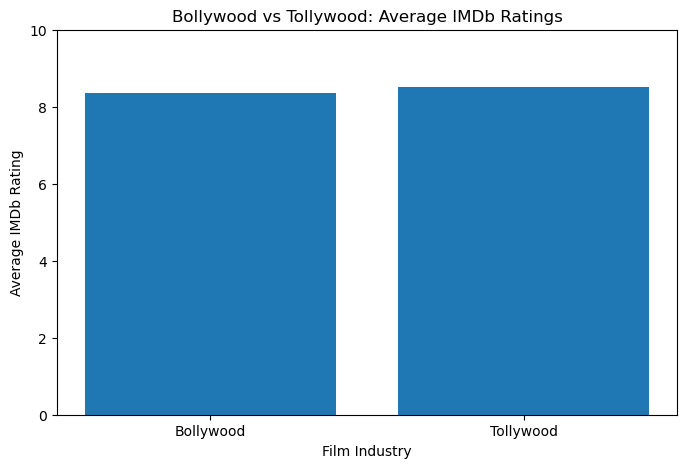

In [41]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(
    industry_ratings.index,
    industry_ratings.values
)

plt.title("Bollywood vs Tollywood: Average IMDb Ratings")
plt.xlabel("Film Industry")
plt.ylabel("Average IMDb Rating")
plt.ylim(0, 10)

plt.show()

In [42]:
import os

print("Current folder:", os.getcwd())
print("Project CSV files are saved in the current folder.")

Current folder: C:\Users\Shant\Downloads\webscrap_project
Project CSV files are saved in the current folder.
